# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertirse documentos escaneados y entrevistas en audio peruanos en un archivo de texto estructurado y buscable?

| Ítem | Detalle |
|---|---|
| Fecha de extracción | 2026-10-25 |
| Documentos (25) | Wikimedia Commons (PD, CC BY 2.0, CC BY-SA 3.0/4.0) e Internet Archive (impresos peruanos 1791–1901 en dominio público; John Carter Brown Library, UIUC, BHL). Detalle por archivo en `datos/fuentes.csv` |
| Audio | **OpenSLR 73** – *Crowdsourced high-quality Peruvian Spanish speech* (Google, CC BY-SA 4.0) + 6 entrevistas/lecturas en español peruano de **Wikimedia Commons** (CC BY-SA 4.0) |
| OCR | PaddleOCR 3.x, pipeline PP-OCRv5 `lang=es` (versión exacta impresa abajo) · alternativo: EasyOCR (lang=es) |
| ASR | faster-whisper `small` (CPU, int8, VAD Silero, `language=es`) · alternativo: NVIDIA Parakeet-TDT 0.6B v3 (ONNX int8, sherpa-onnx) |
| Diarización | pyannote-segmentation-3.0 + embeddings 3D-Speaker ERes2Net + clustering (sherpa-onnx, sin token de HF) |
| Entorno | Python 3.11 (`uv venv`), equivalente a `uv sync --group docai` / `--group audio` de las sesiones |

El código reutilizable está en `pipeline/` (`ocr.py`, `voz.py`, `preparar_audio.py`). Las inferencias se cachean en `datos/raw/` (no versionado), por lo que el notebook se re-ejecuta rápido.

In [1]:
import sys, hashlib, json, re, platform
from pathlib import Path
import pandas as pd, numpy as np
import plotly.express as px, plotly.io as pio
pio.renderers.default = "notebook_connected+png"   # PNG para que los gráficos se vean en GitHub
sys.path.insert(0, "pipeline")
import ocr, voz
import paddleocr, faster_whisper, sherpa_onnx, easyocr
pd.set_option("display.max_colwidth", 120)
print("Python", platform.python_version())
print("PaddleOCR", paddleocr.__version__, "| faster-whisper", faster_whisper.__version__,
      "| sherpa-onnx", sherpa_onnx.__version__, "| EasyOCR", easyocr.__version__)

C:\Users\VVillafuerte\Documents\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


Python 3.11.17
PaddleOCR 3.4.1 | faster-whisper 1.2.1 | sherpa-onnx 2.0.0 | EasyOCR 1.7.2


## 1. Corpus A — Documentos (25: 8 impresos, 8 fotos, 9 manuscritos)

In [2]:
cat = pd.read_csv("datos/raw/documentos/catalogo_documentos.csv")
desc_doc = pd.read_csv("datos/raw/documentos/descartes_documentos.csv")
print(cat.tipo.value_counts().to_dict())
print("Candidatos descartados en la recolección:", len(desc_doc))
desc_doc.motivo.str.split(":").str[0].str.strip().value_counts().head(10)

{'manuscrito': 9, 'impreso': 8, 'foto': 8}
Candidatos descartados en la recolección: 31


motivo
resolución insuficiente (500 px de ancho)                                                                           2
no usado                                                                                                            2
duplicado (mismo diploma que Socgeolima.jpg, escaneo de menor calidad)                                              1
sin texto (es una pintura de la firma de la capitulación)                                                           1
ilegible (manuscrito a 362x550 px, demasiado pequeño)                                                               1
no es escaneo ni fotografía (diseño gráfico digital) y contiene el correo electrónico de una persona viva           1
datos personales (documento de identificación o pase personal; excluido por la regla de documentos de identidad)    1
datos personales (pasaporte), no descargado                                                                         1
datos personales (DNI, licencias, visas), categor

### Limpieza: duplicados por hash de archivo

In [3]:
def sha1(p): return hashlib.sha1(Path(p).read_bytes()).hexdigest()
cat["sha1_local"] = cat.archivo.map(sha1)
dups = cat[cat.duplicated("sha1_local", keep="first")]
print("Duplicados exactos:", len(dups))
cat = cat.drop_duplicates("sha1_local")

Duplicados exactos: 0


### OCR con PaddleOCR
Parámetros: `lang="es"` (modelo latino PP-OCRv5), sin clasificador de orientación ni *unwarping*, `text_det_limit_side_len=1600`.
Preprocesamiento común (también para EasyOCR): orientación EXIF, RGB, lado mayor ≤ 1600 px.
Se guarda el JSON crudo por documento en `datos/raw/documentos/ocr_crudo/` y recortes de las 3 primeras líneas detectadas en `datos/raw/documentos/recortes/`.

In [4]:
res = {r.id: ocr.paddle(r.archivo) for r in cat.itertuples()}
cat["texto_ocr"] = cat.id.map(lambda i: res[i]["texto"])
cat["modelo_ocr"] = cat.id.map(lambda i: res[i]["modelo"])
cat["conf_media"] = cat.id.map(lambda i: np.mean(res[i]["scores"]) if res[i]["scores"] else 0)
cat["n_lineas"] = cat.id.map(lambda i: len(res[i]["lineas"]))
cat["seg_ocr"] = cat.id.map(lambda i: res[i]["segundos_proceso"])
cat.groupby("tipo")[["conf_media", "n_lineas", "seg_ocr"]].mean().round(2)

,conf_media,n_lineas,seg_ocr
tipo,,,
foto,0.82,44.38,11.95
impreso,0.88,73.88,21.88
manuscrito,0.57,50.11,13.10


### Descartes por ilegibilidad
Criterio: se marca un documento si el OCR devuelve menos de 20 caracteres **o** confianza media < 0.5. Los marcados se revisaron visualmente: son legibles para una persona (la baja confianza refleja la dificultad del OCR con caligrafía antigua o reflejos), por lo que **se conservan** como casos difíciles y no se descarta ninguno. Además, en la recolección se descartaron 31 candidatos (tabla anterior) y se reemplazaron hasta completar 25.

In [5]:
cat["n_car"] = cat.texto_ocr.str.len()
ilegibles = cat[(cat.n_car < 20) | (cat.conf_media < 0.5)]
print("Marcados por baja confianza (revisados y conservados):", len(ilegibles))
ilegibles[["id", "tipo", "n_car", "conf_media"]]

Marcados por baja confianza (revisados y conservados): 4


,id,tipo,n_car,conf_media
8,doc_009,foto,845,0.496930
16,doc_017,manuscrito,438,0.415676
21,doc_022,manuscrito,213,0.464245
24,doc_025,manuscrito,225,0.453094


## 2. Corpus B — Audio

**OpenSLR 73** trae enunciados cortos (~5 s) de hablantes peruanos. Con `pipeline/preparar_audio.py` se arman **20 clips de ~95 s**, cada uno concatenando enunciados de **un mismo hablante** (10 mujeres, 10 hombres, semilla 42), con 0.6 s de silencio entre enunciados. La transcripción humana oficial de OpenSLR se conserva como `referencia_fuente`.
A esto se suman **6 grabaciones de Wikimedia Commons** (entrevistas callejeras, ferias con ruido/música, una conferencia y una lectura de Wikipedia hablada), que aportan **varios hablantes** y condiciones difíciles.

In [6]:
ol = pd.read_csv("datos/raw/audio/catalogo_openslr.csv")
ex = pd.read_csv("datos/raw/audio/extra/catalogo_extra.csv")
ex["archivo_audio"] = "datos/raw/audio/extra/" + ex.id + ".wav"
ex["id_orig"] = ex.id
ex["id"] = [f"clip_{21 + i:03d}" for i in range(len(ex))]
ex["fuente"] = "Wikimedia Commons (" + ex.licencia + ")"
ol["condicion"] = "lectura en estudio (crowdsourcing)"; ol["n_hablantes_esperado"] = 1; ol["titulo"] = "OpenSLR 73 hablante " + ol.hablante_fuente.astype(str)
aud = pd.concat([ol[["id","archivo_audio","fuente","fuente_url","titulo","condicion","n_hablantes_esperado","referencia_fuente"]],
                 ex[["id","archivo_audio","fuente","fuente_url","titulo","condicion","n_hablantes_esperado","id_orig"]]], ignore_index=True)
aud["sha1_local"] = aud.archivo_audio.map(sha1)
print("Duplicados por hash:", aud.duplicated("sha1_local").sum())
aud = aud.drop_duplicates("sha1_local")
aud[["id", "fuente", "condicion", "n_hablantes_esperado"]].tail(8)

Duplicados por hash: 0


,id,fuente,condicion,n_hablantes_esperado
18,clip_019,OpenSLR 73 es_pe (CC BY-SA 4.0),lectura en estudio (crowdsourcing),1
19,clip_020,OpenSLR 73 es_pe (CC BY-SA 4.0),lectura en estudio (crowdsourcing),1
20,clip_021,Wikimedia Commons (CC BY-SA 4.0 (https://creativecommons.org/licenses/by-sa/4.0)),exterior/ruido (calle),3
21,clip_022,Wikimedia Commons (CC BY-SA 4.0 (https://creativecommons.org/licenses/by-sa/4.0)),"exterior/ruido (evento), nivel bajo (-40 dB medio)",2
22,clip_023,Wikimedia Commons (CC BY-SA 4.0 (https://creativecommons.org/licenses/by-sa/4.0)),ruido/música (feria),2
23,clip_024,Wikimedia Commons (CC BY-SA 4.0 (https://creativecommons.org/licenses/by-sa/4.0)),ruido/música (feria gastronómica),2
24,clip_025,Wikimedia Commons (CC BY-SA 4.0 (https://creativecommons.org/licenses/by-sa/4.0)),"exterior (conferencia de prensa, Plaza San Martín)",2
25,clip_026,Wikimedia Commons (CC BY-SA 4.0 (https://creativecommons.org/licenses/by-sa/4.0)),estudio/casero (lectura),1


### ASR: faster-whisper `small` + VAD
`language="es"`, `vad_filter=True` (Silero), `beam_size=5`, `condition_on_previous_text=False` (reduce alucinaciones en bucle). CPU int8.

In [7]:
asr = {r.id: voz.whisper(r.archivo_audio) for r in aud.itertuples()}
aud["duracion_seg"] = aud.id.map(lambda i: round(asr[i]["duracion_seg"], 1))
aud["voz_seg"] = aud.id.map(lambda i: round(sum(s["fin"] - s["inicio"] for s in asr[i]["segmentos"]), 1))
aud["rtf_whisper"] = aud.id.map(lambda i: asr[i]["segundos_proceso"] / asr[i]["duracion_seg"])
print(f"Total: {len(aud)} clips, {aud.duracion_seg.sum()/60:.1f} min  |  RTF medio whisper-small CPU: {aud.rtf_whisper.mean():.2f}")

Total: 26 clips, 50.5 min  |  RTF medio whisper-small CPU: 1.27


### Descartes: audios sin voz
Criterio: se descarta un clip si el VAD detecta < 10 s de voz o el ASR devuelve < 5 palabras.

In [8]:
aud["n_palabras_asr"] = aud.id.map(lambda i: len(asr[i]["texto"].split()))
sin_voz = aud[(aud.voz_seg < 10) | (aud.n_palabras_asr < 5)]
print("Audios descartados por falta de voz:", len(sin_voz))
display(sin_voz[["id", "duracion_seg", "voz_seg", "n_palabras_asr"]])
rech = pd.read_csv("datos/raw/audio/extra/rechazados_extra.csv")
print("Candidatos de audio descartados en la recolección:", len(rech))
aud = aud.drop(sin_voz.index)

Audios descartados por falta de voz: 0


,id,duracion_seg,voz_seg,n_palabras_asr


Candidatos de audio descartados en la recolección: 11


### Diarización (audios multihablante de Commons)
Se diariza la entrevista multihablante `clip_021` (pyannote-seg-3.0 + ERes2Net, número de hablantes fijado a 3 según la descripción del archivo; con umbral automático 0.6 el clustering sobresegmentaba en 19 hablantes, por eso se fija el número). En el resto de grabaciones de Commons `n_hablantes` se toma de los metadatos por falta de tiempo de cómputo y se asigna a cada segmento ASR el hablante con mayor solapamiento temporal. Se exportan SRT y TXT con marcas `[HABLANTE_n]`.

In [9]:
aud["n_hablantes"] = aud.n_hablantes_esperado.astype(int)   # OpenSLR = 1; Commons = según metadatos, salvo los diarizados
DIARIZAR = ["clip_021"]  # entrevista en El Agustino, 3 hablantes (entrevistadora + 2 vendedoras)
for r in aud[aud.id.isin(DIARIZAR)].itertuples():
    turnos = voz.diarizar(r.archivo_audio, n_hablantes=int(r.n_hablantes_esperado))
    segs = voz.asignar_hablantes(asr[r.id]["segmentos"], turnos)
    aud.loc[aud.id == r.id, "n_hablantes"] = len({s["hablante"] for s in segs if s["hablante"] != "HABLANTE_?"})
    asr[r.id]["texto"] = voz.texto_con_hablantes(segs)
aud["texto_asr"] = aud.id.map(lambda i: asr[i]["texto"])
aud["modelo_asr"] = aud.id.map(lambda i: asr[i]["modelo"])
aud[aud.id.isin(ex.id)][["id", "condicion", "n_hablantes_esperado", "n_hablantes"]]

,id,condicion,n_hablantes_esperado,n_hablantes
20,clip_021,exterior/ruido (calle),3,3
21,clip_022,"exterior/ruido (evento), nivel bajo (-40 dB medio)",2,2
22,clip_023,ruido/música (feria),2,2
23,clip_024,ruido/música (feria gastronómica),2,2
24,clip_025,"exterior (conferencia de prensa, Plaza San Martín)",2,2
25,clip_026,estudio/casero (lectura),1,1


## 3. Seudonimización
Procedimiento: (0) el diccionario de personas privadas se guarda en `datos/raw/privados.json` (no versionado) para no publicar los nombres reales; (1) reglas automáticas para DNI (8 dígitos), teléfonos, correos; (2) diccionario de **personas privadas** identificadas en la revisión humana de los textos y metadatos (entrevistados/as de Commons). Personajes históricos y autoridades públicas en placas o documentos oficiales (Grau, Prat, San Martín, alcaldes en placas) **no** se sustituyen porque no son datos personales privados. El procedimiento automático se complementó con lectura de todos los textos de audio de Commons.

In [10]:
PRIVADOS = json.load(open("datos/raw/privados.json", encoding="utf-8"))  # diccionario nombre real -> seudónimo; NO versionado (datos/raw/)
REGLAS = {r"\b\d{8}\b": "[DNI]", r"\b9\d{2}[ -]?\d{3}[ -]?\d{3}\b": "[TELEFONO]", r"[\w.]+@[\w.]+\.\w+": "[EMAIL]"}
def seudonimizar(t):
    n = 0
    for real, s in PRIVADOS.items():
        t, k = re.subn(r"\b" + re.escape(real) + r"\b", s, t, flags=re.I); n += k
    for pat, s in REGLAS.items():
        t, k = re.subn(pat, s, t); n += k
    return t, n
for df, col in [(cat, "texto_ocr"), (aud, "texto_asr"), (aud, "titulo"), (cat, "titulo")]:
    out = df[col].map(seudonimizar)
    df[col] = out.str[0]; df["entidades_reemplazadas"] = df.get("entidades_reemplazadas", 0) + out.str[1]
print("Entidades reemplazadas — documentos:", cat.entidades_reemplazadas.sum(), "| audio:", aud.entidades_reemplazadas.sum())
# exportación SRT/TXT ya seudonimizada
for r in aud.itertuples():
    segs = [dict(x, texto=seudonimizar(x["texto"])[0]) for x in asr[r.id]["segmentos"]]
    voz.exportar(r.id, segs)
display(aud[aud.entidades_reemplazadas > 0][["id", "entidades_reemplazadas"]])
print(open("datos/raw/audio/salidas/clip_021.srt", encoding="utf-8").read()[:700])

Entidades reemplazadas — documentos:

 1 | audio: 15


,id,entidades_reemplazadas
20,clip_021,9
23,clip_024,1
24,clip_025,3
25,clip_026,2


1
00:00:00,020 --> 00:00:05,580
[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a

2
00:00:05,580 --> 00:00:10,179
[HABLANTE_1] hacer entrevistas cerca del fútbol como unión de masas. Estoy con las señoras

3
00:00:10,179 --> 00:00:16,260
[HABLANTE_1] PERSONA_A. ¿Estáis PERSONA_B? Muy bien. Voy a comenzar con la primera

4
00:00:16,260 --> 00:00:22,219
[HABLANTE_1] pregunta y es ¿qué expectativas tienen ante este partido?

5
00:00:22,219 --> 00:00:30,820
[HABLANTE_2] Que la afición se encuentra motivado para ganar este partido.

6
00:00:30,820 --> 00:00:32,320
[HABLANTE_1] ¿Me puede decir su nombre?

7
00:00:32,320 --> 00:00:33,820
[HABLANTE_3] PERSO


## 4. Análisis exploratorio

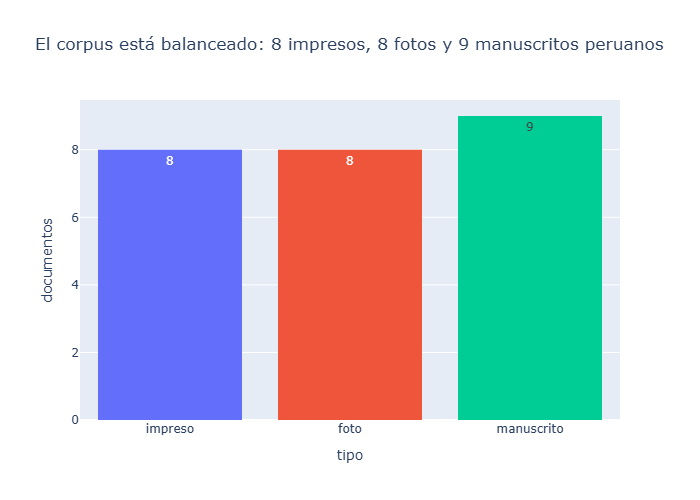

In [11]:
fig = px.histogram(cat, x="tipo", color="tipo", text_auto=True,
    title="El corpus está balanceado: 8 impresos, 8 fotos y 9 manuscritos peruanos")
fig.update_layout(showlegend=False, yaxis_title="documentos"); fig.show()

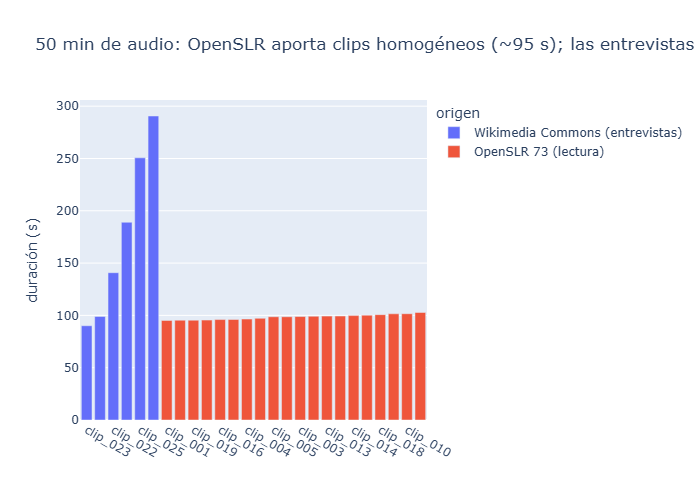

In [12]:
aud["origen"] = np.where(aud.id.isin(ex.id), "Wikimedia Commons (entrevistas)", "OpenSLR 73 (lectura)")
fig = px.bar(aud.sort_values("duracion_seg"), x="id", y="duracion_seg", color="origen",
    title=f"{aud.duracion_seg.sum()/60:.0f} min de audio: OpenSLR aporta clips homogéneos (~95 s); las entrevistas de Commons son más largas y variables")
fig.update_layout(yaxis_title="duración (s)", xaxis_title=""); fig.show()

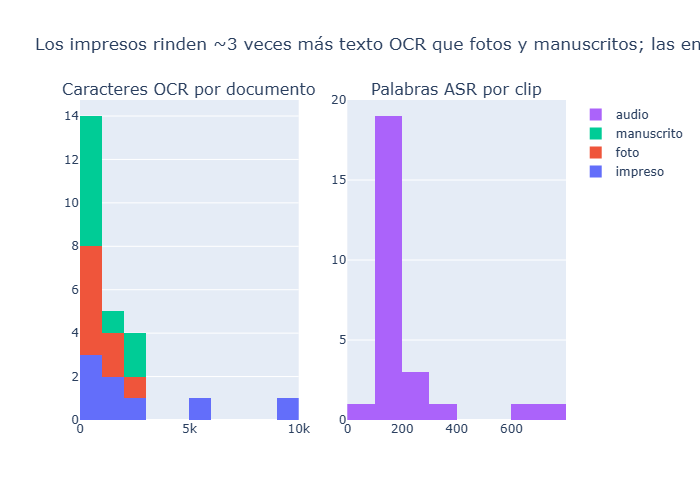

In [13]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
fig = make_subplots(1, 2, subplot_titles=("Caracteres OCR por documento", "Palabras ASR por clip"))
for t in cat.tipo.unique():
    fig.add_trace(go.Histogram(x=cat[cat.tipo == t].n_car, name=t, nbinsx=12), 1, 1)
fig.add_trace(go.Histogram(x=aud.n_palabras_asr, name="audio", nbinsx=12), 1, 2)
fig.update_layout(barmode="stack", title="Los impresos rinden ~3 veces más texto OCR que fotos y manuscritos; las entrevistas de Commons triplican las palabras de los clips de lectura")
fig.show()

## 5. Validación: extremos de longitud

In [14]:
print("OCR más largos:"); display(cat.nlargest(3, "n_car")[["id", "tipo", "n_car", "titulo"]])
print("OCR más cortos:"); display(cat.nsmallest(3, "n_car")[["id", "tipo", "n_car", "titulo"]])
print("Clips más largos:"); display(aud.nlargest(3, "duracion_seg")[["id", "duracion_seg", "n_palabras_asr", "titulo"]])
print("Clips más cortos:"); display(aud.nsmallest(3, "duracion_seg")[["id", "duracion_seg", "n_palabras_asr", "titulo"]])

OCR más largos:


,id,tipo,n_car,titulo
2,doc_003,impreso,9817,"El Peruano (diario oficial) - Índice del primer semestre de 1901, p. 15"
1,doc_002,impreso,5972,"Bando del virrey José Fernando de Abascal, Lima, febrero de 1813"
12,doc_013,foto,2863,"Placa con biografía de Miguel Grau, Miraflores (Lima)"


OCR más cortos:


,id,tipo,n_car,titulo
15,doc_016,foto,52,"Placa del Monasterio de Nazarenas Carmelitas Descalzas, Lima"
14,doc_015,foto,154,"Inscripción del monumento a José Quiñones, San Isidro (Lima)"
21,doc_022,manuscrito,213,"Partida de bautismo de Micaela Villegas 'La Perricholi', Lima 1748"


Clips más largos:


,id,duracion_seg,n_palabras_asr,titulo
25,clip_026,290.6,777,Es-Huaca Santa Catalina-article.ogg
24,clip_025,250.6,636,Entrevista-PERSONA_C-organización de mujeres indígenas-fiestas patrias.ogg
20,clip_021,189.0,366,Entrevista 2 en la Av. Rivagüero - El Agustino.ogg


Clips más cortos:


,id,duracion_seg,n_palabras_asr,titulo
22,clip_023,90.1,182,Entrevista en Magdalena por Fiestas Patrias Perú 2022 (1).webm
0,clip_001,95.2,163,OpenSLR 73 hablante 7508
16,clip_017,95.4,128,OpenSLR 73 hablante 610


Los extremos coinciden con los histogramas: los impresos densos (gacetas, bandos) son los más largos, y las placas breves y manuscritos difíciles los más cortos. En audio, las entrevistas de Commons concentran las duraciones extremas.

## 6. Exportación

In [15]:
cat["texto_referencia"] = ""
aud["idioma"] = "es (español peruano según la fuente)"
aud["texto_referencia"] = ""
documentos = cat[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia", "titulo", "fuente_url", "conf_media"]]
transcripciones = aud[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia",
                       "fuente", "fuente_url", "titulo", "condicion", "origen"]]
documentos.to_csv("datos/documentos.csv", index=False, encoding="utf-8")
transcripciones.to_csv("datos/transcripciones.csv", index=False, encoding="utf-8")
# referencia humana de OpenSLR (se usa en la Parte 2)
aud[["id", "referencia_fuente"]].dropna().to_csv("datos/referencia_openslr.csv", index=False, encoding="utf-8")
fuentes = pd.concat([
    pd.DataFrame({"id": cat.id, "modalidad": "documento", "fuente_url": cat.fuente_url, "licencia": cat.licencia,
                  "acceso": "Descarga directa desde la URL (imagen ≤2000 px); atribución: " + cat.autor.astype(str)}),
    pd.DataFrame({"id": aud.id, "modalidad": "audio", "fuente_url": aud.fuente_url,
                  "licencia": np.where(aud.origen.str.startswith("OpenSLR"), "CC BY-SA 4.0", aud.fuente.str.extract(r"\((.*)\)")[0]),
                  "acceso": np.where(aud.origen.str.startswith("OpenSLR"),
                                     "Descargar es_pe_female.zip / es_pe_male.zip de openslr.org/73 y ejecutar pipeline/preparar_audio.py",
                                     "Descargar de Wikimedia Commons y convertir a WAV 16 kHz mono con ffmpeg")})])
fuentes.to_csv("datos/fuentes.csv", index=False, encoding="utf-8")
for n, d in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(n, d.shape)
display(documentos.head()); display(transcripciones.head())

documentos (25, 10)
transcripciones (26, 13)
fuentes (51, 5)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,titulo,fuente_url,conf_media
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Internet Archive - John Carter Brown Library (Dominio público),GACETA\nESTRAORDINARIA.\nLEL GOBIERNO DE LIMA\nDel miercoles 22 de Diciembre de 1824.\nEjercito Libertador.—Cuartel ...,"PaddleOCR 3.4.1 PP-OCRv5 mobile det + latin_PP-OCRv5_mobile_rec (es, max_lado=1600, sin unwarping)",,"Gaceta Extraordinaria del Gobierno de Lima, 22 de diciembre de 1824",https://archive.org/details/gacetadelgobiern01brow,0.971090
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Internet Archive - John Carter Brown Library (Dominio público),"30\nNo en Medica-\nD. JOSE FERNANDO DE ABASCAL Y SOUSA,\nMARQUES DE LA CONCORDIA ESPAÑOLADEL PERU, CABALLERO GRAN CR...","PaddleOCR 3.4.1 PP-OCRv5 mobile det + latin_PP-OCRv5_mobile_rec (es, max_lado=1600, sin unwarping)",,"Bando del virrey José Fernando de Abascal, Lima, febrero de 1813",https://archive.org/details/djosefernandodea08spai,0.935508
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Internet Archive - University of Illinois Urbana-Champaign (Dominio público),"INDICE DEL PRIMER SEMESTRE DE 1901\n15\n00\nPÁG.\nPÁG.\nResolución aprobando el gasto de S. 1,166.25 verificado por ...","PaddleOCR 3.4.1 PP-OCRv5 mobile det + latin_PP-OCRv5_mobile_rec (es, max_lado=1600, sin unwarping)",,"El Peruano (diario oficial) - Índice del primer semestre de 1901, p. 15",https://archive.org/details/elperuano61peru,0.924038
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Internet Archive - Biodiversity Heritage Library / AMNH (Dominio público),"-4-\ndita 79.ª ; empieza otra loma - Se llega á la base, 11.8, al otro\nlado.-Se descansó.\nContinuando, 11.55, se a...","PaddleOCR 3.4.1 PP-OCRv5 mobile det + latin_PP-OCRv5_mobile_rec (es, max_lado=1600, sin unwarping)",,Boletín de la Sociedad Geográfica de Lima - itinerario de Sarayacu a Santa Catalina (p. 4),https://archive.org/details/boletndelasocied1719soci,0.928925
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Internet Archive - John Carter Brown Library (Dominio público),Señor Doctor Don Matias de la Torre y Tagle.\nSefior Don Joseph Gutierrez Oficial de ia Contaduria de\nTributos.\nS...,"PaddleOCR 3.4.1 PP-OCRv5 mobile det + latin_PP-OCRv5_mobile_rec (es, max_lado=1600, sin unwarping)",,"Mercurio Peruano, tomo I (1791) - lista de suscriptores",https://archive.org/details/mercurioperuanod01cale,0.969121


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,fuente,fuente_url,titulo,condicion,origen
0,clip_001,datos/raw/audio/clip_001.wav,95.2,es (español peruano según la fuente),Resérvame ocho boletos por favor para la sesión de las nueve de la noche. Hay nuevos canales de audio en cada una de...,"faster-whisper small (cpu int8, lang=es, VAD=on, beam=5)",1,,OpenSLR 73 es_pe (CC BY-SA 4.0),"https://www.openslr.org/73/ (female, hablante 07508)",OpenSLR 73 hablante 7508,lectura en estudio (crowdsourcing),OpenSLR 73 (lectura)
1,clip_002,datos/raw/audio/clip_002.wav,98.7,es (español peruano según la fuente),"¿De qué edad son tus hijos, Álex? Recomiéndame una escuela de cine. Oye, ¿me ayudas a buscar una compañía de mudanza...","faster-whisper small (cpu int8, lang=es, VAD=on, beam=5)",1,,OpenSLR 73 es_pe (CC BY-SA 4.0),"https://www.openslr.org/73/ (female, hablante 07049)",OpenSLR 73 hablante 7049,lectura en estudio (crowdsourcing),OpenSLR 73 (lectura)
2,clip_003,datos/raw/audio/clip_003.wav,98.9,es (español peruano según la fuente),En ese canal salen películas de niños a esas horas. Estoy aburrido con la música de mi teléfono. Quiero que me recom...,"faster-whisper small (cpu int8, lang=es, VAD=on, beam=5)",1,,OpenSLR 73 es_pe (CC BY-SA 4.0),"https://www.openslr.org/73/ (female, hablante 02436)",OpenSLR 73 hablante 2436,lectura en estudio (crowdsourcing),OpenSLR 73 (lectura)
3,clip_004,datos/raw/audio/clip_004.wav,96.5,es (español peruano según la fuente),No quiero estar me mojando toda la tarde. La mermelada de salsamora es muy fácil de hacer. Se han caído 13 edificios...,"faster-whisper small (cpu int8, lang=es, VAD=on, beam=5)",1,,OpenSLR 73 es_pe (CC BY-SA 4.0),"https://www.openslr.org/73/ (female, hablante 04310)",OpenSLR 73 hablante 4310,lectura en estudio (crowdsourcing),OpenSLR 73 (lectura)
4,clip_005,datos/raw/audio/clip_005.wav,98.7,es (español peruano según la fuente),Lo que dicen en internet puede ser mentira o no. Mis hijos me están pidiendo que les baje unos podcasts. No he tenid...,"faster-whisper small (cpu int8, lang=es, VAD=on, beam=5)",1,,OpenSLR 73 es_pe (CC BY-SA 4.0),"https://www.openslr.org/73/ (female, hablante 02484)",OpenSLR 73 hablante 2484,lectura en estudio (crowdsourcing),OpenSLR 73 (lectura)
